# Modellierung – Modellvergleich und Bewertung

Wir bewerten die gespeicherten Vorhersagen mit MAE, MASE, WAPE und Bias. Die Modellauswahl erfolgt anhand der jährlichen Validierung. Zusätzlich prüfen wir die Stabilität und den Nutzen der Baugenehmigunge.

## 1. Vorhersagen laden
 Jährliche Validierung und monatliche Sensitivitätsprüfung werden getrennt ausgewertet. Der bekannte Test folgt im nächsten Notebook.

In [ ]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


project_dir = Path(
    r"C:\Users\mmatavela\Desktop\House_Demand_Forecasting"
)
results_dir = project_dir / "ergebnisse" / "modellierung"
figures_dir = results_dir / "grafiken"
figures_dir.mkdir(parents=True, exist_ok=True)

predictions_data = pd.read_csv(results_dir / "all_predictions.csv")
run_protocol = json.loads(
    (results_dir / "run_protocol.json").read_text(encoding="utf-8")
)

annual_predictions = predictions_data.loc[
    predictions_data["origin"].isin(run_protocol["annual_origins"])
].copy()
monthly_predictions = predictions_data.loc[
    predictions_data["origin"].isin(run_protocol["monthly_origins"])
].copy()

assert annual_predictions.groupby("model").size().eq(48).all()
assert monthly_predictions.groupby("model").size().eq(240).all()

#alle Modelle werden auf denselben Prognosefällen bewertet werden.
for evaluation_data in [annual_predictions, monthly_predictions]:
    reference_cases = set(
        evaluation_data.loc[
            evaluation_data["model"] == "Seasonal Naive",
            ["origin", "target", "horizon"]
        ].itertuples(index=False, name=None)
    )
    for model_name, model_data in evaluation_data.groupby("model"):
        model_cases = set(
            model_data[["origin", "target", "horizon"]].itertuples(
                index=False, name=None
            )
        )
        assert model_cases == reference_cases

dark_blue = "#173F63"
blue = "#4B91BF"
light_blue = "#93B4D0"
red = "#B52835"

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 10
})
print("Vorhersagen geladen und gemeinsame Prognosefälle geprüft.")

Vorhersagen geladen und gemeinsame Prognosefälle geprüft.


## 2. Fehlermaße und Modellvergleich

MAE beschreibt die durchschnittliche absolute Abweichung in Listings. MASE setzt die Fehler zur saisonalen Veränderung der Trainingshistorie ins Verhältnis. WAPE misst die summierten absoluten Fehler relativ zu den tatsächlichen Werten.

Bias zeigt die Fehlerrichtung: positiv bedeutet Überschätzung, negativ Unterschätzung. Die Modellauswahl erfolgt nach dem jährlichen MAE.

In [4]:
def calculate_metrics(data_frame):
    metric_rows = []

    for model_name, model_data in data_frame.groupby("model"):
        errors = model_data["prediction"] - model_data["actual"]
        absolute_errors = errors.abs()
        actual_total = model_data["actual"].sum()

        if actual_total <= 0:
            raise ValueError("WAPE benötigt eine positive Zielwertsumme.")

        metric_rows.append({
            "model": model_name,
            "mae": absolute_errors.mean(),
            "mase": model_data["scaled_error"].mean(),
            "wape": 100 * absolute_errors.sum() / actual_total,
            "bias": errors.mean()
        })

    return (
        pd.DataFrame(metric_rows)
        .set_index("model")
        .sort_values("mae")
    )


annual_metrics = calculate_metrics(annual_predictions)
monthly_metrics = calculate_metrics(monthly_predictions)

best_ets = annual_metrics.loc[
    annual_metrics.index.str.startswith("ETS")
].index[0]

selected_models = [
    "Naive", "Seasonal Naive", "Seasonal Mean 3Y", best_ets, "SARIMA"
]
best_ridge_models = {}

for group_name in ["Minimal", "Basis", "Permits"]:
    best_ridge = annual_metrics.loc[
        annual_metrics.index.str.startswith(f"Ridge {group_name} ")
    ].index[0]
    best_ridge_models[group_name] = best_ridge
    selected_models.append(best_ridge)

selected_models.extend(["GB Basis", "GB Permits"])
selected_model = annual_metrics.index[0]
model_comparison = annual_metrics.loc[selected_models].copy()
reference_mae = annual_metrics.loc["Seasonal Naive", "mae"]
model_comparison["gain_percent"] = (
    100 * (1 - model_comparison["mae"] / reference_mae)
)

comparison_display = model_comparison.rename(columns={
    "mae": "MAE",
    "mase": "MASE",
    "wape": "WAPE (%)",
    "bias": "Bias (Listings)",
    "gain_percent": "Vorteil zur Referenz (%)"
})
display(comparison_display.style.format({
    "MAE": "{:.1f}",
    "MASE": "{:.3f}",
    "WAPE (%)": "{:.1f}",
    "Bias (Listings)": "{:+.1f}",
    "Vorteil zur Referenz (%)": "{:+.1f}"
}))
print("Ausgewählter Modellkandidat:", selected_model)

model_comparison.to_csv(results_dir / "comparison.csv")
annual_metrics.to_csv(results_dir / "all_annual_variants.csv")
monthly_metrics.to_csv(results_dir / "all_monthly_variants.csv")
selection = {
    "selected_model": selected_model,
    "selected_models": selected_models
}
(results_dir / "selection.json").write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding="utf-8"
)


,MAE,MASE,WAPE (%),Bias (Listings),Vorteil zur Referenz (%)
model,,,,,
Naive,817.5,1.345,35.5,+691.0,-27.4
Seasonal Naive,641.8,1.057,27.9,+329.8,+0.0
Seasonal Mean 3Y,539.1,0.882,23.4,+398.6,+16.0
ETS ohne Trend,493.1,0.793,21.4,+84.4,+23.2
SARIMA,579.7,0.951,25.2,+253.8,+9.7
Ridge Minimal a=1000,564.2,0.923,24.5,+460.0,+12.1
Ridge Basis a=10,446.8,0.727,19.4,+189.3,+30.4
Ridge Permits a=10,453.2,0.739,19.7,+206.7,+29.4
GB Basis,431.2,0.704,18.8,+294.8,+32.8


Ausgewählter Modellkandidat: GB Basis


268

## 3. Stabilität über Horizonte und Jahre

Die Grafiken vergleichen den MAE nach Prognosehorizont und jährlichem Prognosestart. So erkennen wir, ob ein Modell durchgehend oder nur in einzelnen Zeiträumen besser abschneidet.

Bei den jährlichen August-Starts sind Prognosehorizont und Zielmonat miteinander verknüpft.

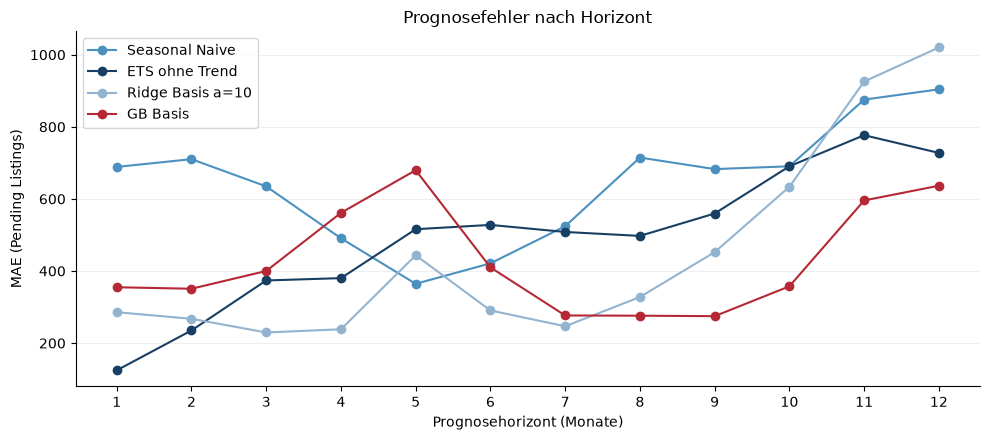

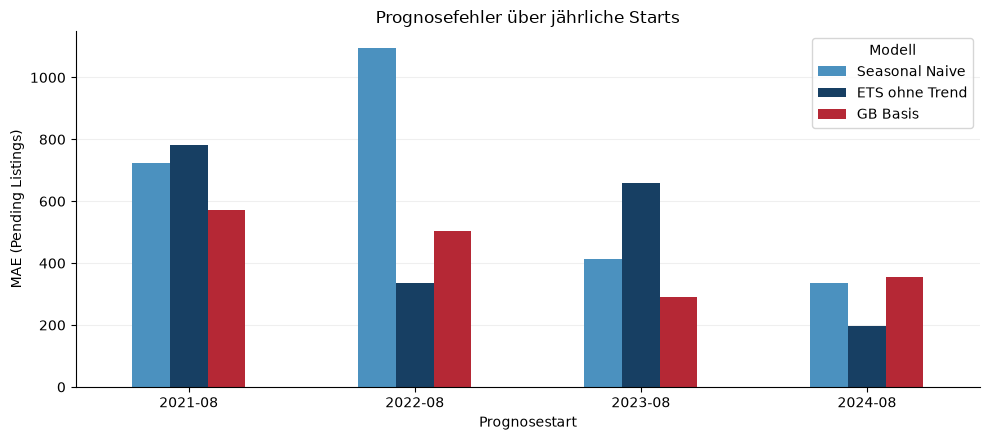

In [5]:
horizon_models = list(dict.fromkeys([
    "Seasonal Naive", best_ets, best_ridge_models["Basis"], selected_model
]))
horizon_colors = [blue, dark_blue, light_blue, red]

horizon_errors = (
    annual_predictions.loc[
        annual_predictions["model"].isin(horizon_models)
    ]
    .groupby(["horizon", "model"])["ae"]
    .mean()
    .unstack("model")
)

fig, ax = plt.subplots()
for model_name, color in zip(horizon_models, horizon_colors):
    ax.plot(
        horizon_errors.index, horizon_errors[model_name],
        marker="o", linewidth=1.5, color=color, label=model_name
    )
ax.set(
    title="Prognosefehler nach Horizont",
    xlabel="Prognosehorizont (Monate)",
    ylabel="MAE (Pending Listings)"
)
ax.set_xticks(range(1, 13))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "01_horizon_errors.png", dpi=200)
plt.show()


year_models = list(dict.fromkeys([
    "Seasonal Naive", best_ets, selected_model
]))
year_errors = (
    annual_predictions.loc[
        annual_predictions["model"].isin(year_models)
    ]
    .groupby(["origin", "model"])["ae"]
    .mean()
    .unstack("model")[year_models]
)

ax = year_errors.plot.bar(
    color=[blue, dark_blue, red], rot=0, figsize=(10, 4.5)
)
ax.set(
    title="Prognosefehler über jährliche Starts",
    xlabel="Prognosestart",
    ylabel="MAE (Pending Listings)"
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(title="Modell")
ax.figure.tight_layout()
ax.figure.savefig(figures_dir / "02_annual_errors.png", dpi=200)
plt.show()

horizon_errors.to_csv(results_dir / "annual_by_horizon.csv")
year_errors.to_csv(results_dir / "annual_by_origin.csv")

## 4. Zusatznutzen der Baugenehmigungen

Wir vergleichen Basis und Permits auf identischen Prognosefällen. Ridge verwendet in beiden Varianten Alpha 10; auch die Boosting-Parameter bleiben gleich.

Ein positiver Vorteil bedeutet weniger Fehler durch Baugenehmigungen, ein negativer Wert mehr Fehler.

In [6]:
permits_rows = []
model_pairs = [
    ("Ridge", "Ridge Basis a=10", "Ridge Permits a=10"),
    ("Gradient Boosting", "GB Basis", "GB Permits")
]
evaluation_sets = {
    "Jährlich": annual_predictions,
    "Monatlich": monthly_predictions
}

for evaluation_name, evaluation_data in evaluation_sets.items():
    for model_family, basis_name, permits_name in model_pairs:
        basis_data = (
            evaluation_data.loc[evaluation_data["model"] == basis_name]
            .set_index(["origin", "horizon"])
            .sort_index()
        )
        permits_data = (
            evaluation_data.loc[evaluation_data["model"] == permits_name]
            .set_index(["origin", "horizon"])
            .sort_index()
        )
        assert basis_data.index.equals(permits_data.index)
        assert np.allclose(basis_data["actual"], permits_data["actual"])

        basis_mae = basis_data["ae"].mean()
        permits_mae = permits_data["ae"].mean()
        permits_rows.append({
            "evaluation": evaluation_name,
            "model_family": model_family,
            "mae_without_permits": basis_mae,
            "mae_with_permits": permits_mae,
            "gain_percent": 100 * (1 - permits_mae / basis_mae)
        })

permits_comparison = pd.DataFrame(permits_rows)
display(permits_comparison.rename(columns={
    "evaluation": "Prüfung",
    "model_family": "Modell",
    "mae_without_permits": "MAE ohne Permits",
    "mae_with_permits": "MAE mit Permits",
    "gain_percent": "Vorteil (%)"
}).round(2))
permits_comparison.to_csv(
    results_dir / "permits_matched_comparison.csv", index=False
)

,Prüfung,Modell,MAE ohne Permits,MAE mit Permits,Vorteil (%)
0,Jährlich,Ridge,446.78,453.23,-1.44
1,Jährlich,Gradient Boosting,431.16,431.34,-0.04
2,Monatlich,Ridge,386.17,372.56,3.53
3,Monatlich,Gradient Boosting,353.55,358.42,-1.38


## 5. Fehlertoleranz und Zusammenfassung

Wir prüfen den ausgewählten Kandidaten gegen den WAPE-Zielwert von 12 % und die maximale Toleranz von 15 %. Diese Grenzen wurden als Projektkriterium durch unser Team ergänzt.

WAPE wird insgesamt und je Horizont berechnet. Die Grenze gilt für aggregierte Fehler, nicht als garantierte maximale Monatsabweichung.

,Modell,Prognosefälle,MAE,MASE,WAPE (%),Bias (Listings),Bewertung
Jährliche Validierung,GB Basis,48,431.2,0.704,18.8,+294.8,Über der Toleranz
Monatliche Sensitivität,GB Basis,240,353.5,0.538,15.6,+29.1,Über der Toleranz


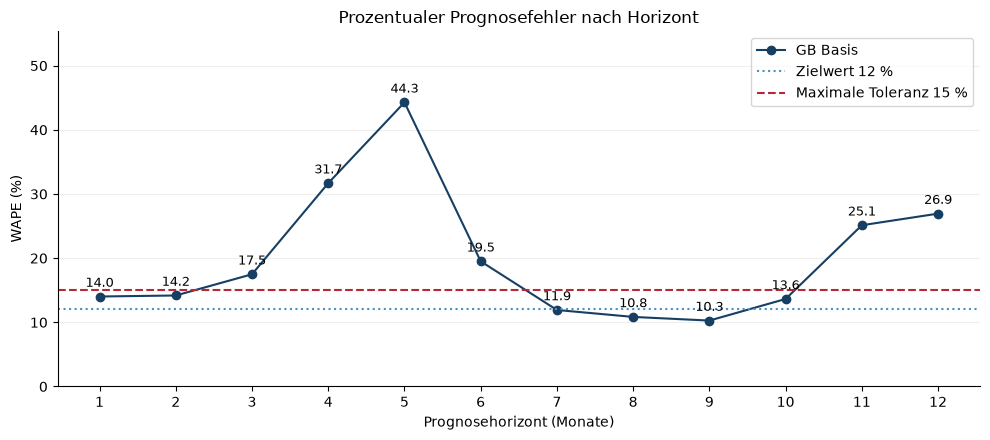

,Horizonte (Monate),Prognosefälle,WAPE (%),Bewertung
0,1–3,12,15.2,Über der Toleranz
1,4–6,12,30.5,Über der Toleranz
2,7–9,12,11.0,Ziel erreicht
3,10–12,12,21.6,Über der Toleranz


In [7]:
target_wape = 12
maximum_wape = 15


def classify_wape(wape_value):
    if wape_value <= target_wape:
        return "Ziel erreicht"
    if wape_value <= maximum_wape:
        return "Innerhalb der Toleranz"
    return "Über der Toleranz"


evaluation_summary = pd.DataFrame(
    [annual_metrics.loc[selected_model], monthly_metrics.loc[selected_model]],
    index=["Jährliche Validierung", "Monatliche Sensitivität"]
)
evaluation_summary["model"] = selected_model
evaluation_summary["cases"] = [
    len(annual_predictions.loc[annual_predictions["model"] == selected_model]),
    len(monthly_predictions.loc[monthly_predictions["model"] == selected_model])
]
evaluation_summary["assessment"] = (
    evaluation_summary["wape"].apply(classify_wape)
)
summary_display = evaluation_summary[
    ["model", "cases", "mae", "mase", "wape", "bias", "assessment"]
].rename(columns={
    "model": "Modell",
    "cases": "Prognosefälle",
    "mae": "MAE",
    "mase": "MASE",
    "wape": "WAPE (%)",
    "bias": "Bias (Listings)",
    "assessment": "Bewertung"
})
display(summary_display.style.format({
    "MAE": "{:.1f}",
    "MASE": "{:.3f}",
    "WAPE (%)": "{:.1f}",
    "Bias (Listings)": "{:+.1f}"
}))

selected_predictions = annual_predictions.loc[
    annual_predictions["model"] == selected_model
]
horizon_totals = selected_predictions.groupby("horizon").agg(
    absolute_error_sum=("ae", "sum"), actual_sum=("actual", "sum")
)
horizon_wape = (
    100 * horizon_totals["absolute_error_sum"] / horizon_totals["actual_sum"]
)

fig, ax = plt.subplots()
ax.plot(
    horizon_wape.index, horizon_wape.values,
    marker="o", color=dark_blue, linewidth=1.5, label=selected_model
)
ax.axhline(target_wape, color=blue, linestyle=":", label="Zielwert 12 %")
ax.axhline(
    maximum_wape, color=red, linestyle="--", label="Maximale Toleranz 15 %"
)
for horizon, wape_value in horizon_wape.items():
    ax.annotate(
        f"{wape_value:.1f}", (horizon, wape_value),
        xytext=(0, 7), textcoords="offset points", ha="center", fontsize=9
    )
ax.set(
    title="Prozentualer Prognosefehler nach Horizont",
    xlabel="Prognosehorizont (Monate)", ylabel="WAPE (%)"
)
ax.set_xticks(range(1, 13))
ax.set_ylim(0, max(float(horizon_wape.max()), maximum_wape) * 1.25)
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(figures_dir / "03_wape_by_horizon.png", dpi=200)
plt.show()


horizon_groups = {
    "1–3": [1, 2, 3],
    "4–6": [4, 5, 6],
    "7–9": [7, 8, 9],
    "10–12": [10, 11, 12]
}
group_rows = []
for group_name, horizons in horizon_groups.items():
    group_data = selected_predictions.loc[
        selected_predictions["horizon"].isin(horizons)
    ]
    group_wape = 100 * group_data["ae"].sum() / group_data["actual"].sum()
    group_rows.append({
        "horizons": group_name,
        "cases": len(group_data),
        "wape": group_wape,
        "assessment": classify_wape(group_wape)
    })
horizon_group_summary = pd.DataFrame(group_rows)
display(horizon_group_summary.rename(columns={
    "horizons": "Horizonte (Monate)",
    "cases": "Prognosefälle",
    "wape": "WAPE (%)",
    "assessment": "Bewertung"
}).round(1))

evaluation_summary.to_csv(results_dir / "evaluation_summary.csv")
horizon_wape.rename("wape").to_csv(results_dir / "annual_wape_by_horizon.csv")
horizon_group_summary.to_csv(
    results_dir / "horizon_group_summary.csv", index=False
)